In [2]:
import cartopy.crs as ccrs
import numpy as np
import xarray as xr
import pyremo as pr
import cmaps
import glob
from REMO2020_mod import modelclass, season_mean, open_mfdataset, domainclass, plotclass, remo_plotter
from REMO2020TEB_mod import eobs_wind_open

In [3]:
from dask.distributed import Client, progress
import dask
dask.config.set({'temporary_directory': '/scratch/g/g300096/dask/tmp'})
client = Client()
client

/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 43879 instead
  warnings.warn(
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/contextlib.py:142: UserWarning: Creating scratch directories is taking a surprisingly long time. (1.78s) This is often due to running workers on a network file system. Consider specifying a local-directory to point workers to write scratch data to a local disk.
  next(self.gen)


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/g300096/levante-spawner-preset//proxy/43879/status,
Dashboard: /user/g300096/levante-spawner-preset//proxy/43879/status,Workers: 16
Total threads: 256,Total memory: 235.37 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45371,Workers: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/43879/status,Total threads: 256
Started: Just now,Total memory: 235.37 GiB
Comm: tcp://127.0.0.1:36957,Total threads: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/36869/status,Memory: 14.71 GiB
Nanny: tcp://127.0.0.1:40471,


In [4]:
# define the runs to be plotted
modelruns =[] # init

modelruns.append(modelclass("036041","REMO2020",True))
modelruns.append(modelclass("036043","REMO2020 TEB",True))
modelruns.append(modelclass("036042","REMO2020 iMOVE",True))
modelruns.append(modelclass("036044","REMO2020 TEB iMOVE",True))

In [5]:
# give path, prefix and suffix (the main name for the plots)
figpath = './figures/'
prefix = 'eobs_wind_seas_'
suffix = 'REMO2020_main'

In [6]:
# REMO and EOBS datapath
rdata = './data_in/model_data/'
edata = './data_in/E-OBS/'

In [7]:
# define star year and end year
ystart=2011
yend=2020

In [8]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [9]:
# Load the lake mask
lake_mask = xr.open_dataset(rdata+"FLake_input/flake_v3_glcc_defD10.0m_frac_EUR-11.nc")["FLFRA"]

In [10]:
# lake fraction cut-off limit
clake = 0.5

In [11]:
# E-OBS version
eobv='v32.0e'

In [12]:
# set the minimum number days with data per month to be included
dlim=21

In [13]:
# lake fraction cut-off limit
clake = 0.5

In [14]:
# Target grid
trggrid = "EUR-11"

In [15]:
# Eobs variable
var = "fg" # name of the variable to be read in
eobsfile = edata+eobv+"/day/var/"+var+"/"+var+"_ens_mean_0.1deg_reg_"+eobv+".nc"
eobs_mdata, final_mask = eobs_wind_open(var,eobsfile,ystart,yend,trggrid,dlim,lake_mask,clake)

/home/g/g300096/scripts/remo-analysis/teb2025/main_analysis/REMO2020TEB_mod.py:34: UserWarning: The specified chunks separate the stored chunks along dimension "latitude" starting at index 201. This could degrade performance. Instead, consider rechunking after loading.
  eobs_daydata = xr.open_dataset(eobsfile, chunks={"time": 1, "latitude": 201, "longitude": 464}, use_cftime=False).sel(time=slice(str(ystart), str(yend)))
/home/g/g300096/scripts/remo-analysis/teb2025/main_analysis/REMO2020TEB_mod.py:34: UserWarning: The specified chunks separate the stored chunks along dimension "longitude" starting at index 464. This could degrade performance. Instead, consider rechunking after loading.
  eobs_daydata = xr.open_dataset(eobsfile, chunks={"time": 1, "latitude": 201, "longitude": 464}, use_cftime=False).sel(time=slice(str(ystart), str(yend)))
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 31.9

In [16]:
yearlist = np.arange(ystart,yend+1)
for obj in modelruns:
    obj.filenames = []
    for year in yearlist:
        pattern = rdata+obj.userexp+"/results/"+str(year)+"/xm/e"+obj.userexp+"m*.nc"
        obj.filenames += glob.glob(pattern)
    obj.filenames.sort()

In [17]:
# Set halo zone length (will be cutted out)
halo = 8

In [18]:
# calculate the wind difference to EOBS
ii = 0
for obj in modelruns:
    ds = open_mfdataset(obj.filenames, parallel=False, chunks='auto')
    wim = pr.parse_dates(ds.WIND10) # open data
#    t2m = t2m.squeeze(dim=t2m.dims[1],drop=True)
    # Merge data (get identical coordinates)
    wim_all = xr.merge([wim, final_mask.rename("mask"), eobs_mdata.rename("eobs_m_data")], compat="override", join="override")
    # Calculate absolute values
    if(ii == 0):
        abs_vals = wim_all[["eobs_m_data"]].where(wim_all.mask, drop=False).compute()
        abs_vals_mean = season_mean(abs_vals).eobs_m_data
        abs_vals_mean = abs_vals_mean.where(abs_vals_mean > 0.0, drop=False) # remove zeros
        abs_vals_mean = abs_vals_mean.isel(rlat=slice(halo+1,abs_vals_mean.sizes["rlat"]-halo+1), rlon=slice(halo+1,abs_vals_mean.sizes["rlon"]-halo+1)).compute()
    # get identical coordinates
    final_tmp = xr.merge([wim_all,abs_vals.eobs_m_data.rename("abs_vals")], compat="override", join="override")
    # apply masking (eobs+lake) and subtract the values, finally making seasonal means
    obj.vardiff = season_mean(final_tmp.WIND10.where(final_tmp.mask,drop=False) - final_tmp.abs_vals).squeeze()
    obj.vardiff = obj.vardiff.isel(rlat=slice(halo+1,obj.vardiff.sizes["rlat"]-halo+1), rlon=slice(halo+1,obj.vardiff.sizes["rlon"]-halo+1)).compute()
    # not supported, set to zero
    obj.mask = np.zeros(len(seasons))
    # Increase counter
    ii = ii + 1
    #t_stat
    if(obj.r2020file):
        pole = (ds.rotated_latitude_longitude.grid_north_pole_longitude,ds.rotated_latitude_longitude.grid_north_pole_latitude)
        rotated_pole = ccrs.RotatedPole(pole[0], pole[1])
        extent = ([ds.rlon.min(), ds.rlon.max(), ds.rlat.min(), ds.rlat.max()], rotated_pole)
    # clean memory
    del ds, wim, wim_all, final_tmp
# clean memory
del eobs_mdata, abs_vals

/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 257.96 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch063

In [19]:
# define the domains to be plotted
domaininfo =[] # init
domaininfo.append(domainclass("EU",[-22.5,47.5,30,72.5], hspace=0.35))

In [20]:
# define plotclasses for absolute and difference (model) plots
absplotc = plotclass(label='10-m wind speed [m/s]', lspace=np.linspace(0,1,32), vmin=0, vmax=5, linvert=False, cmapp=cmaps.BlAqGrYeOrReVi200)
modplotc = plotclass(label='$\Delta$10-m wind speed [m/s]', lspace=np.linspace(0,1,16), vmin=-2, vmax=2, linvert=False, cmapp=cmaps.BlueWhiteOrangeRed)

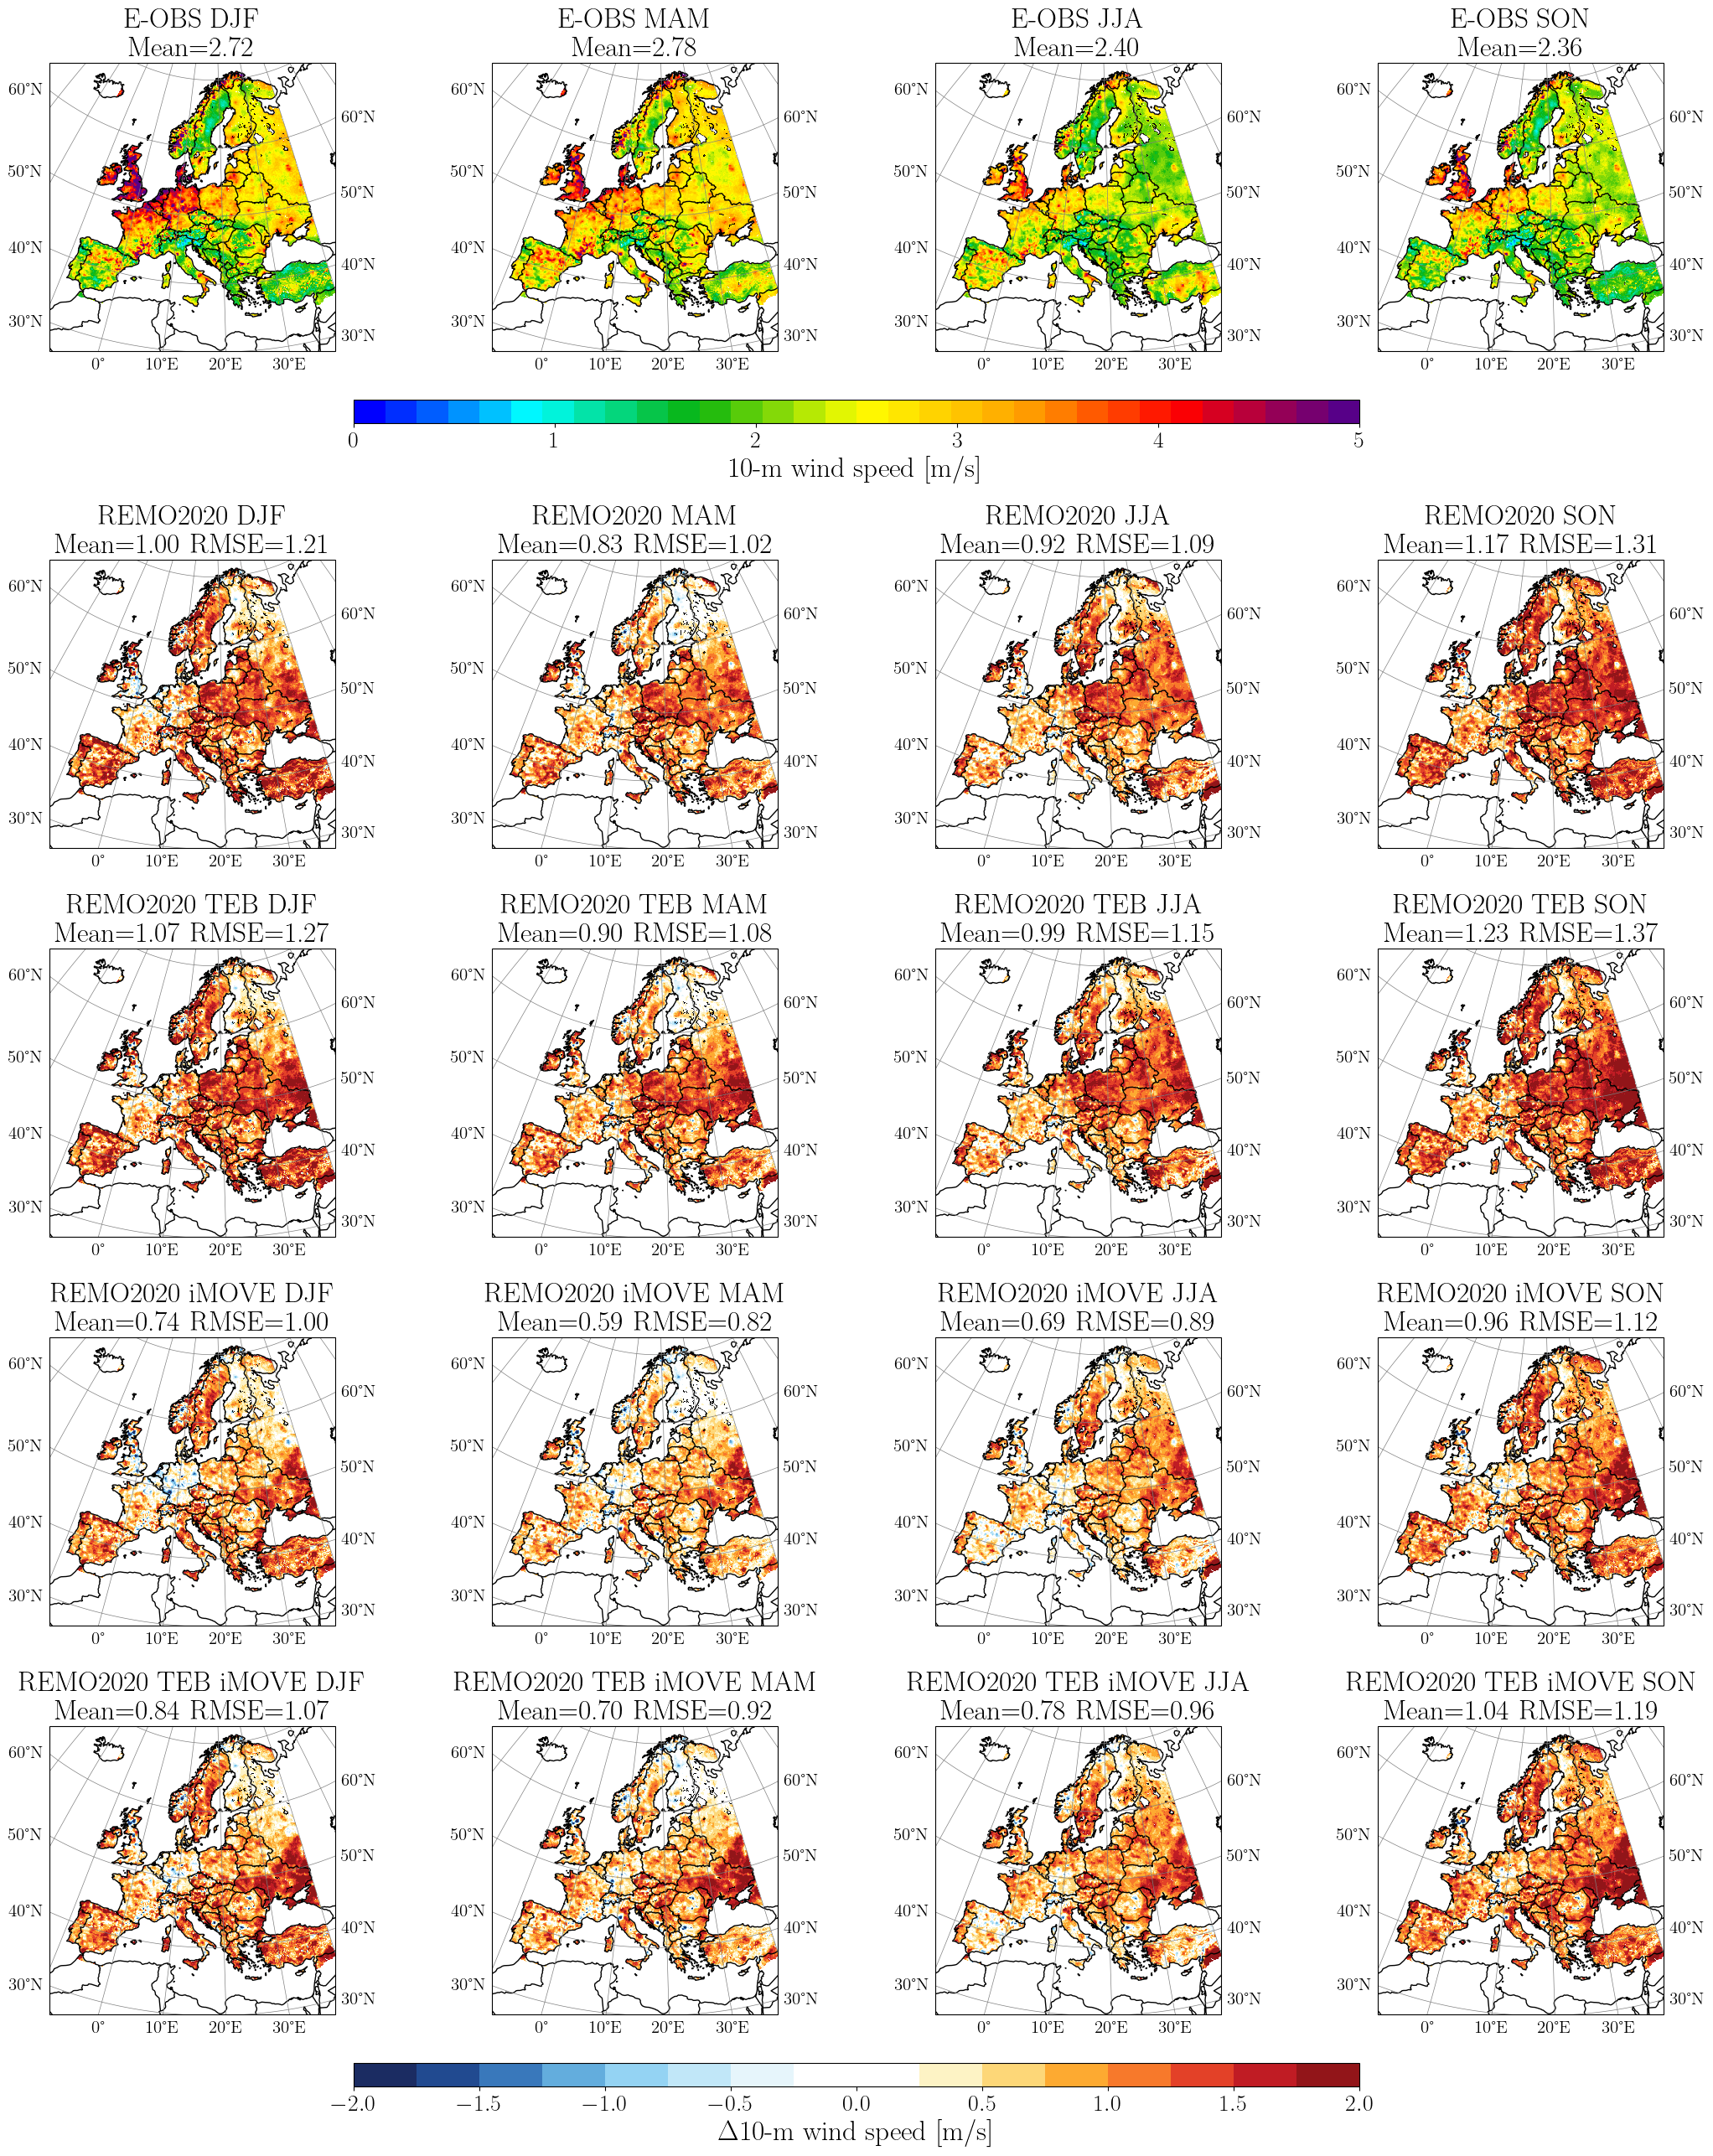

In [21]:
# Loop over domains
for dom in range(len(domaininfo)):
    # Create figure name
    figname=prefix+domaininfo[dom].name+'_'+suffix
    # Call plotter
    remo_plotter(absplotc,modplotc,domaininfo[dom],modelruns,"E-OBS",abs_vals_mean,seasons,pole,False,figpath,figname)